In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 10000

# =========================================================
# 1. CUSTOMER / LOAN CHARACTERISTICS
# =========================================================

df = pd.DataFrame({
    'loan_id': np.arange(100001, 100001 + n),

    'age': np.random.randint(21, 66, n),

    'annual_income': np.random.lognormal(
        mean=np.log(60000),
        sigma=0.45,
        size=n
    ).round(0),

    'employment_years': np.random.randint(0, 31, n),

    'credit_score': np.clip(
        np.random.normal(690, 55, n),
        500,
        850
    ).round(0),

    'dti': np.clip(
        np.random.normal(28, 12, n),
        2,
        70
    ).round(2),

    'credit_utilization': np.clip(
        np.random.beta(2.5, 4, n),
        0.01,
        0.99
    ).round(3),

    'num_open_accounts': np.random.poisson(5, n) + 1,

    'delinq_2yrs': np.random.poisson(0.5, n),

    'inq_last_6mths': np.random.poisson(1.2, n),

    'pub_rec': np.random.binomial(1, 0.05, n),

    'total_accounts': np.random.randint(3, 40, n),

    'loan_amount': np.random.lognormal(
        mean=np.log(15000),
        sigma=0.55,
        size=n
    ).round(0),

    'loan_term': np.random.choice(
        [36, 60],
        size=n,
        p=[0.65, 0.35]
    ),

    'interest_rate': np.clip(
        np.random.normal(13, 4, n),
        5,
        30
    ).round(2),

    'loan_purpose': np.random.choice(
        ['debt_consolidation',
         'home_improvement',
         'education',
         'medical',
         'business',
         'personal'],
        size=n,
        p=[0.35, 0.15, 0.10, 0.08, 0.12, 0.20]
    ),

    'home_ownership': np.random.choice(
        ['RENT', 'MORTGAGE', 'OWN'],
        size=n,
        p=[0.45, 0.40, 0.15]
    ),

    'verification_status': np.random.choice(
        ['Verified', 'Source Verified', 'Not Verified'],
        size=n,
        p=[0.35, 0.40, 0.25]
    ),

    'employment_type': np.random.choice(
        ['Salaried', 'Self-employed', 'Contract', 'Other'],
        size=n,
        p=[0.65, 0.18, 0.10, 0.07]
    )
})


# =========================================================
# 2. ORIGINATION DATE
# =========================================================

df['issue_d'] = pd.to_datetime(
    np.random.choice(
        pd.date_range('2018-01-01', '2022-12-01', freq='MS'),
        size=n
    )
)

# Earliest credit history
credit_history_years = np.random.randint(2, 30, n)

df['earliest_cr_line'] = (
    df['issue_d']
    - pd.to_timedelta(credit_history_years * 365, unit='D')
)


# =========================================================
# 3. CREDIT HISTORY MONTHS
# =========================================================

df['credit_history_months'] = (
    (df['issue_d'].dt.year - df['earliest_cr_line'].dt.year) * 12
    + (df['issue_d'].dt.month - df['earliest_cr_line'].dt.month)
)

df['credit_history_months'] = df['credit_history_months'].clip(lower=6)


# =========================================================
# 4. CREDIT LIMIT / CURRENT BALANCE
# =========================================================

# Credit limit somewhat related to income and loan size
df['credit_limit'] = (
    df['loan_amount'] * np.random.uniform(1.1, 1.8, n)
).round(0)

# Current balance
df['current_balance'] = (
    df['loan_amount']
    * np.random.uniform(0.15, 0.95, n)
).round(0)

# Make sure balance doesn't exceed limit
df['current_balance'] = np.minimum(
    df['current_balance'],
    df['credit_limit']
)

# Utilization based on generated balance
df['current_utilization'] = (
    df['current_balance'] / df['credit_limit']
).round(3)


# =========================================================
# 5. PD / DEFAULT GENERATION
# =========================================================
#
# Higher risk:
# - lower credit score
# - higher DTI
# - higher utilization
# - more delinquencies
# - more inquiries
# - public record
# - higher interest rate
#
# Lower risk:
# - higher income
# - longer employment
# - longer credit history
# =========================================================

risk_score = (
    -0.025 * (df['credit_score'] - 700)
    + 0.045 * (df['dti'] - 25)
    + 1.8 * (df['credit_utilization'] - 0.45)
    + 0.55 * df['delinq_2yrs']
    + 0.18 * df['inq_last_6mths']
    + 0.90 * df['pub_rec']
    + 0.025 * (df['interest_rate'] - 12)
    - 0.000004 * (df['annual_income'] - 60000)
    - 0.015 * df['employment_years']
    - 0.0015 * df['credit_history_months']
)

# Convert risk score into probability
base_probability = 1 / (1 + np.exp(-(risk_score - 1.2)))

# Add randomness
df['pd_probability'] = np.clip(
    base_probability,
    0.01,
    0.75
)

# Generate default
df['default'] = np.random.binomial(
    1,
    df['pd_probability']
)


# =========================================================
# 6. LOAN STATUS
# =========================================================

df['loan_status'] = np.where(
    df['default'] == 1,
    np.random.choice(
        ['Charged Off', 'Late (31-120 days)'],
        size=n,
        p=[0.75, 0.25]
    ),
    np.random.choice(
        ['Fully Paid', 'Current'],
        size=n,
        p=[0.30, 0.70]
    )
)


# =========================================================
# 7. EAD VARIABLES
# =========================================================

# Undrawn amount
df['undrawn_amount'] = (
    df['credit_limit'] - df['current_balance']
).clip(lower=0).round(0)

# Credit Conversion Factor
#
# Higher utilization generally means less undrawn
# and therefore smaller additional drawdown.

df['ccf'] = np.clip(
    0.30
    + 0.40 * df['current_utilization']
    + np.random.normal(0, 0.08, n),
    0.05,
    0.95
).round(3)

# For non-defaulted loans, this is still available for
# later EAD modelling.
df['ead'] = (
    df['current_balance']
    + df['ccf'] * df['undrawn_amount']
).round(2)


# =========================================================
# 8. COLLATERAL VARIABLES FOR LGD
# =========================================================

df['collateral_value'] = (
    df['loan_amount']
    * np.random.uniform(0.5, 1.5, n)
).round(0)

df['collateral_type'] = np.random.choice(
    ['None', 'Vehicle', 'Property', 'Other'],
    size=n,
    p=[0.40, 0.30, 0.20, 0.10]
)

# If no collateral, collateral value = 0
df.loc[
    df['collateral_type'] == 'None',
    'collateral_value'
] = 0


# =========================================================
# 9. RECOVERY RATE / LGD
# =========================================================
#
# LGD = 1 - Recovery Rate
#
# Better collateral -> higher recovery
# Higher collateral value -> lower LGD
# Collection costs -> higher LGD
#
# LGD is primarily meaningful for defaulted loans.
# =========================================================

collateral_ratio = np.where(
    df['ead'] > 0,
    df['collateral_value'] / df['ead'],
    0
)

recovery_rate = (
    0.15
    + 0.35 * np.clip(collateral_ratio, 0, 1)
    + 0.05 * (df['credit_score'] - 650) / 200
    + np.random.normal(0, 0.08, n)
)

recovery_rate = np.clip(
    recovery_rate,
    0,
    0.95
)

df['recovery_rate'] = recovery_rate.round(3)

df['lgd'] = (
    1 - df['recovery_rate']
).round(3)


# =========================================================
# 10. RECOVERY AMOUNT
# =========================================================

df['recovery_amount'] = (
    df['ead'] * df['recovery_rate']
).round(2)

# Recovery is 0 for non-defaulted loans
df.loc[
    df['default'] == 0,
    'recovery_amount'
] = 0

# LGD is meaningful primarily for defaulted loans
df.loc[
    df['default'] == 0,
    'lgd'
] = np.nan

df.loc[
    df['default'] == 0,
    'recovery_rate'
] = np.nan


# =========================================================
# 11. COLLECTION COST
# =========================================================

df['collection_cost'] = np.where(
    df['default'] == 1,
    (
        df['ead']
        * np.random.uniform(0.02, 0.08, n)
    ).round(2),
    0
)

# Adjust LGD for collection costs
default_mask = df['default'] == 1

df.loc[default_mask, 'lgd'] = np.clip(
    (
        1
        - (
            df.loc[default_mask, 'recovery_amount']
            - df.loc[default_mask, 'collection_cost']
        )
        / df.loc[default_mask, 'ead']
    ),
    0,
    1
).round(3)


# =========================================================
# 12. ECL
# =========================================================
#
# Expected Credit Loss
#
# ECL = PD × LGD × EAD
#
# For the project, use predicted PD/LGD/EAD later.
# Here we create an actual/synthetic reference version.
# =========================================================

df['ecl'] = (
    df['pd_probability']
    * df['lgd'].fillna(0)
    * df['ead']
).round(2)


# =========================================================
# 13. CLEAN COLUMN ORDER
# =========================================================

columns = [
    'loan_id',
    'issue_d',
    'age',
    'annual_income',
    'employment_years',
    'employment_type',
    'credit_score',
    'credit_history_months',
    'earliest_cr_line',
    'dti',
    'credit_utilization',
    'num_open_accounts',
    'total_accounts',
    'delinq_2yrs',
    'inq_last_6mths',
    'pub_rec',
    'home_ownership',
    'verification_status',
    'loan_amount',
    'loan_term',
    'interest_rate',
    'loan_purpose',
    'credit_limit',
    'current_balance',
    'current_utilization',
    'undrawn_amount',
    'ccf',
    'ead',
    'collateral_type',
    'collateral_value',
    'recovery_amount',
    'recovery_rate',
    'collection_cost',
    'lgd',
    'pd_probability',
    'default',
    'loan_status',
    'ecl'
]

df = df[columns]


# =========================================================
# 14. SAVE DATASET
# =========================================================

df.to_csv(
    'pd_ead_lgd_10000.csv',
    index=False
)

print("Dataset shape:", df.shape)

print("\nDefault rate:")
print(df['default'].mean())

print("\nLoan status:")
print(df['loan_status'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
print(df.head())

Dataset shape: (10000, 38)

Default rate:
0.3325

Loan status:
loan_status
Current               4681
Charged Off           2477
Fully Paid            1994
Late (31-120 days)     848
Name: count, dtype: int64

Missing values:
loan_id                     0
issue_d                     0
age                         0
annual_income               0
employment_years            0
employment_type             0
credit_score                0
credit_history_months       0
earliest_cr_line            0
dti                         0
credit_utilization          0
num_open_accounts           0
total_accounts              0
delinq_2yrs                 0
inq_last_6mths              0
pub_rec                     0
home_ownership              0
verification_status         0
loan_amount                 0
loan_term                   0
interest_rate               0
loan_purpose                0
credit_limit                0
current_balance             0
current_utilization         0
undrawn_amount          

In [2]:
df.shape

(10000, 38)

In [3]:
df_model = df.copy()

In [4]:
pd.set_option('display.max_columns', None)
df_model.head()

,loan_id,issue_d,age,annual_income,employment_years,employment_type,credit_score,credit_history_months,earliest_cr_line,dti,credit_utilization,num_open_accounts,total_accounts,delinq_2yrs,inq_last_6mths,pub_rec,home_ownership,verification_status,loan_amount,loan_term,interest_rate,loan_purpose,credit_limit,current_balance,current_utilization,undrawn_amount,ccf,ead,collateral_type,collateral_value,recovery_amount,recovery_rate,collection_cost,lgd,pd_probability,default,loan_status,ecl
0,100001,2021-01-01,59,51944.0,8,Salaried,700.0,24,2019-01-02,44.68,0.548,6,19,0,1,0,RENT,Not Verified,22143.0,36,12.67,debt_consolidation,27101.0,10372.0,0.383,16729.0,0.368,16528.27,None,0.0,0.00,NaN,0.00,NaN,0.483749,0,Current,0.00
1,100002,2021-12-01,49,26940.0,20,Other,751.0,348,1992-12-08,6.12,0.519,6,24,0,2,0,MORTGAGE,Source Verified,7480.0,36,14.47,debt_consolidation,8404.0,1951.0,0.232,6453.0,0.310,3951.43,None,0.0,0.00,NaN,0.00,NaN,0.030225,0,Current,0.00
2,100003,2022-10-01,35,39305.0,3,Salaried,616.0,324,1995-10-08,34.87,0.174,5,5,0,0,0,RENT,Not Verified,40593.0,36,12.81,personal,63164.0,10515.0,0.166,52649.0,0.292,25888.51,Other,29551.0,0.00,NaN,0.00,NaN,0.603335,0,Current,0.00
3,100004,2021-08-01,63,74354.0,1,Self-employed,594.0,96,2013-08-03,23.95,0.290,6,35,1,2,0,RENT,Not Verified,36472.0,60,8.34,education,57666.0,31231.0,0.542,26435.0,0.519,44950.76,Other,28572.0,0.00,NaN,0.00,NaN,0.750000,0,Current,0.00
4,100005,2020-10-01,28,129866.0,27,Other,647.0,60,2015-10-03,56.88,0.594,2,4,1,1,0,RENT,Not Verified,23166.0,36,7.08,business,39940.0,15444.0,0.387,24496.0,0.484,27300.06,Other,21501.0,10892.72,0.399,1979.37,0.674,0.750000,1,Charged Off,13800.18


In [5]:
df_pd = df.copy()

In [6]:
df_pd.shape

(10000, 38)

In [7]:
df_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 38 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   loan_id                10000 non-null  int64         
 1   issue_d                10000 non-null  datetime64[ns]
 2   age                    10000 non-null  int64         
 3   annual_income          10000 non-null  float64       
 4   employment_years       10000 non-null  int64         
 5   employment_type        10000 non-null  object        
 6   credit_score           10000 non-null  float64       
 7   credit_history_months  10000 non-null  int32         
 8   earliest_cr_line       10000 non-null  datetime64[ns]
 9   dti                    10000 non-null  float64       
 10  credit_utilization     10000 non-null  float64       
 11  num_open_accounts      10000 non-null  int64         
 12  total_accounts         10000 non-null  int64         
 13  de

In [8]:
df_pd.columns

Index(['loan_id', 'issue_d', 'age', 'annual_income', 'employment_years',
       'employment_type', 'credit_score', 'credit_history_months',
       'earliest_cr_line', 'dti', 'credit_utilization', 'num_open_accounts',
       'total_accounts', 'delinq_2yrs', 'inq_last_6mths', 'pub_rec',
       'home_ownership', 'verification_status', 'loan_amount', 'loan_term',
       'interest_rate', 'loan_purpose', 'credit_limit', 'current_balance',
       'current_utilization', 'undrawn_amount', 'ccf', 'ead',
       'collateral_type', 'collateral_value', 'recovery_amount',
       'recovery_rate', 'collection_cost', 'lgd', 'pd_probability', 'default',
       'loan_status', 'ecl'],
      dtype='object')

In [9]:
# select varaible for PD model as customer information and loan related information till disbursement

df_pd = df_pd[['issue_d', 'age', 'annual_income', 'employment_years',
       'employment_type', 'credit_score', 'credit_history_months',
       'earliest_cr_line', 'dti', 'credit_utilization', 'num_open_accounts',
       'total_accounts', 'delinq_2yrs', 'inq_last_6mths', 'pub_rec',
       'home_ownership', 'verification_status', 'loan_amount', 'loan_term',
       'interest_rate', 'loan_purpose','default']]

In [10]:
df_pd.shape

(10000, 22)

# EDA

In [11]:
df_pd.isna().sum().sort_values(ascending=False)  # there is no missing values

,0
issue_d,0
age,0
annual_income,0
employment_years,0
employment_type,0
credit_score,0
credit_history_months,0
earliest_cr_line,0
dti,0
credit_utilization,0


In [12]:
# checking duplicate values

df_pd.duplicated().sum()

np.int64(0)

In [13]:
# chcek for incorrrect values or outliers
df_pd.describe().T


,count,mean,min,25%,50%,75%,max,std
issue_d,10000,2020-06-16 10:56:47.040000,2018-01-01 00:00:00,2019-03-01 00:00:00,2020-07-01 00:00:00,2021-10-01 00:00:00,2022-12-01 00:00:00,NaN
age,10000.0,43.0382,21.0,32.0,43.0,54.0,65.0,12.895611
annual_income,10000.0,66493.3101,10270.0,44321.5,59955.0,81427.5,293659.0,31691.762166
employment_years,10000.0,15.0886,0.0,7.0,15.0,23.0,30.0,8.917674
credit_score,10000.0,689.9974,500.0,652.0,690.0,728.0,850.0,55.298575
credit_history_months,10000.0,186.108,24.0,96.0,180.0,276.0,348.0,97.277962
earliest_cr_line,10000,2004-12-16 16:06:23.040000,1989-01-08 00:00:00,1997-11-06 00:00:00,2005-01-05 00:00:00,2011-12-04 00:00:00,2020-12-01 00:00:00,NaN
dti,10000.0,28.066436,2.0,19.91,27.95,36.0925,70.0,11.907396
credit_utilization,10000.0,0.383334,0.01,0.249,0.37,0.50725,0.958,0.176126
num_open_accounts,10000.0,5.9861,1.0,4.0,6.0,7.0,18.0,2.244418


In [14]:
num_cols = df_pd.select_dtypes(include ='number').columns
cat_cols = df_pd.select_dtypes(include ='object').columns

print('num_cols:',num_cols)
print('cat_cols:',cat_cols)

num_cols: Index(['age', 'annual_income', 'employment_years', 'credit_score',
       'credit_history_months', 'dti', 'credit_utilization',
       'num_open_accounts', 'total_accounts', 'delinq_2yrs', 'inq_last_6mths',
       'pub_rec', 'loan_amount', 'loan_term', 'interest_rate', 'default'],
      dtype='object')
cat_cols: Index(['employment_type', 'home_ownership', 'verification_status',
       'loan_purpose'],
      dtype='object')


In [15]:
df_pd['default'].value_counts()

,count
default,
0,6675
1,3325


In [16]:
df_pd['default'].value_counts(normalize=True)

,proportion
default,
0,0.6675
1,0.3325


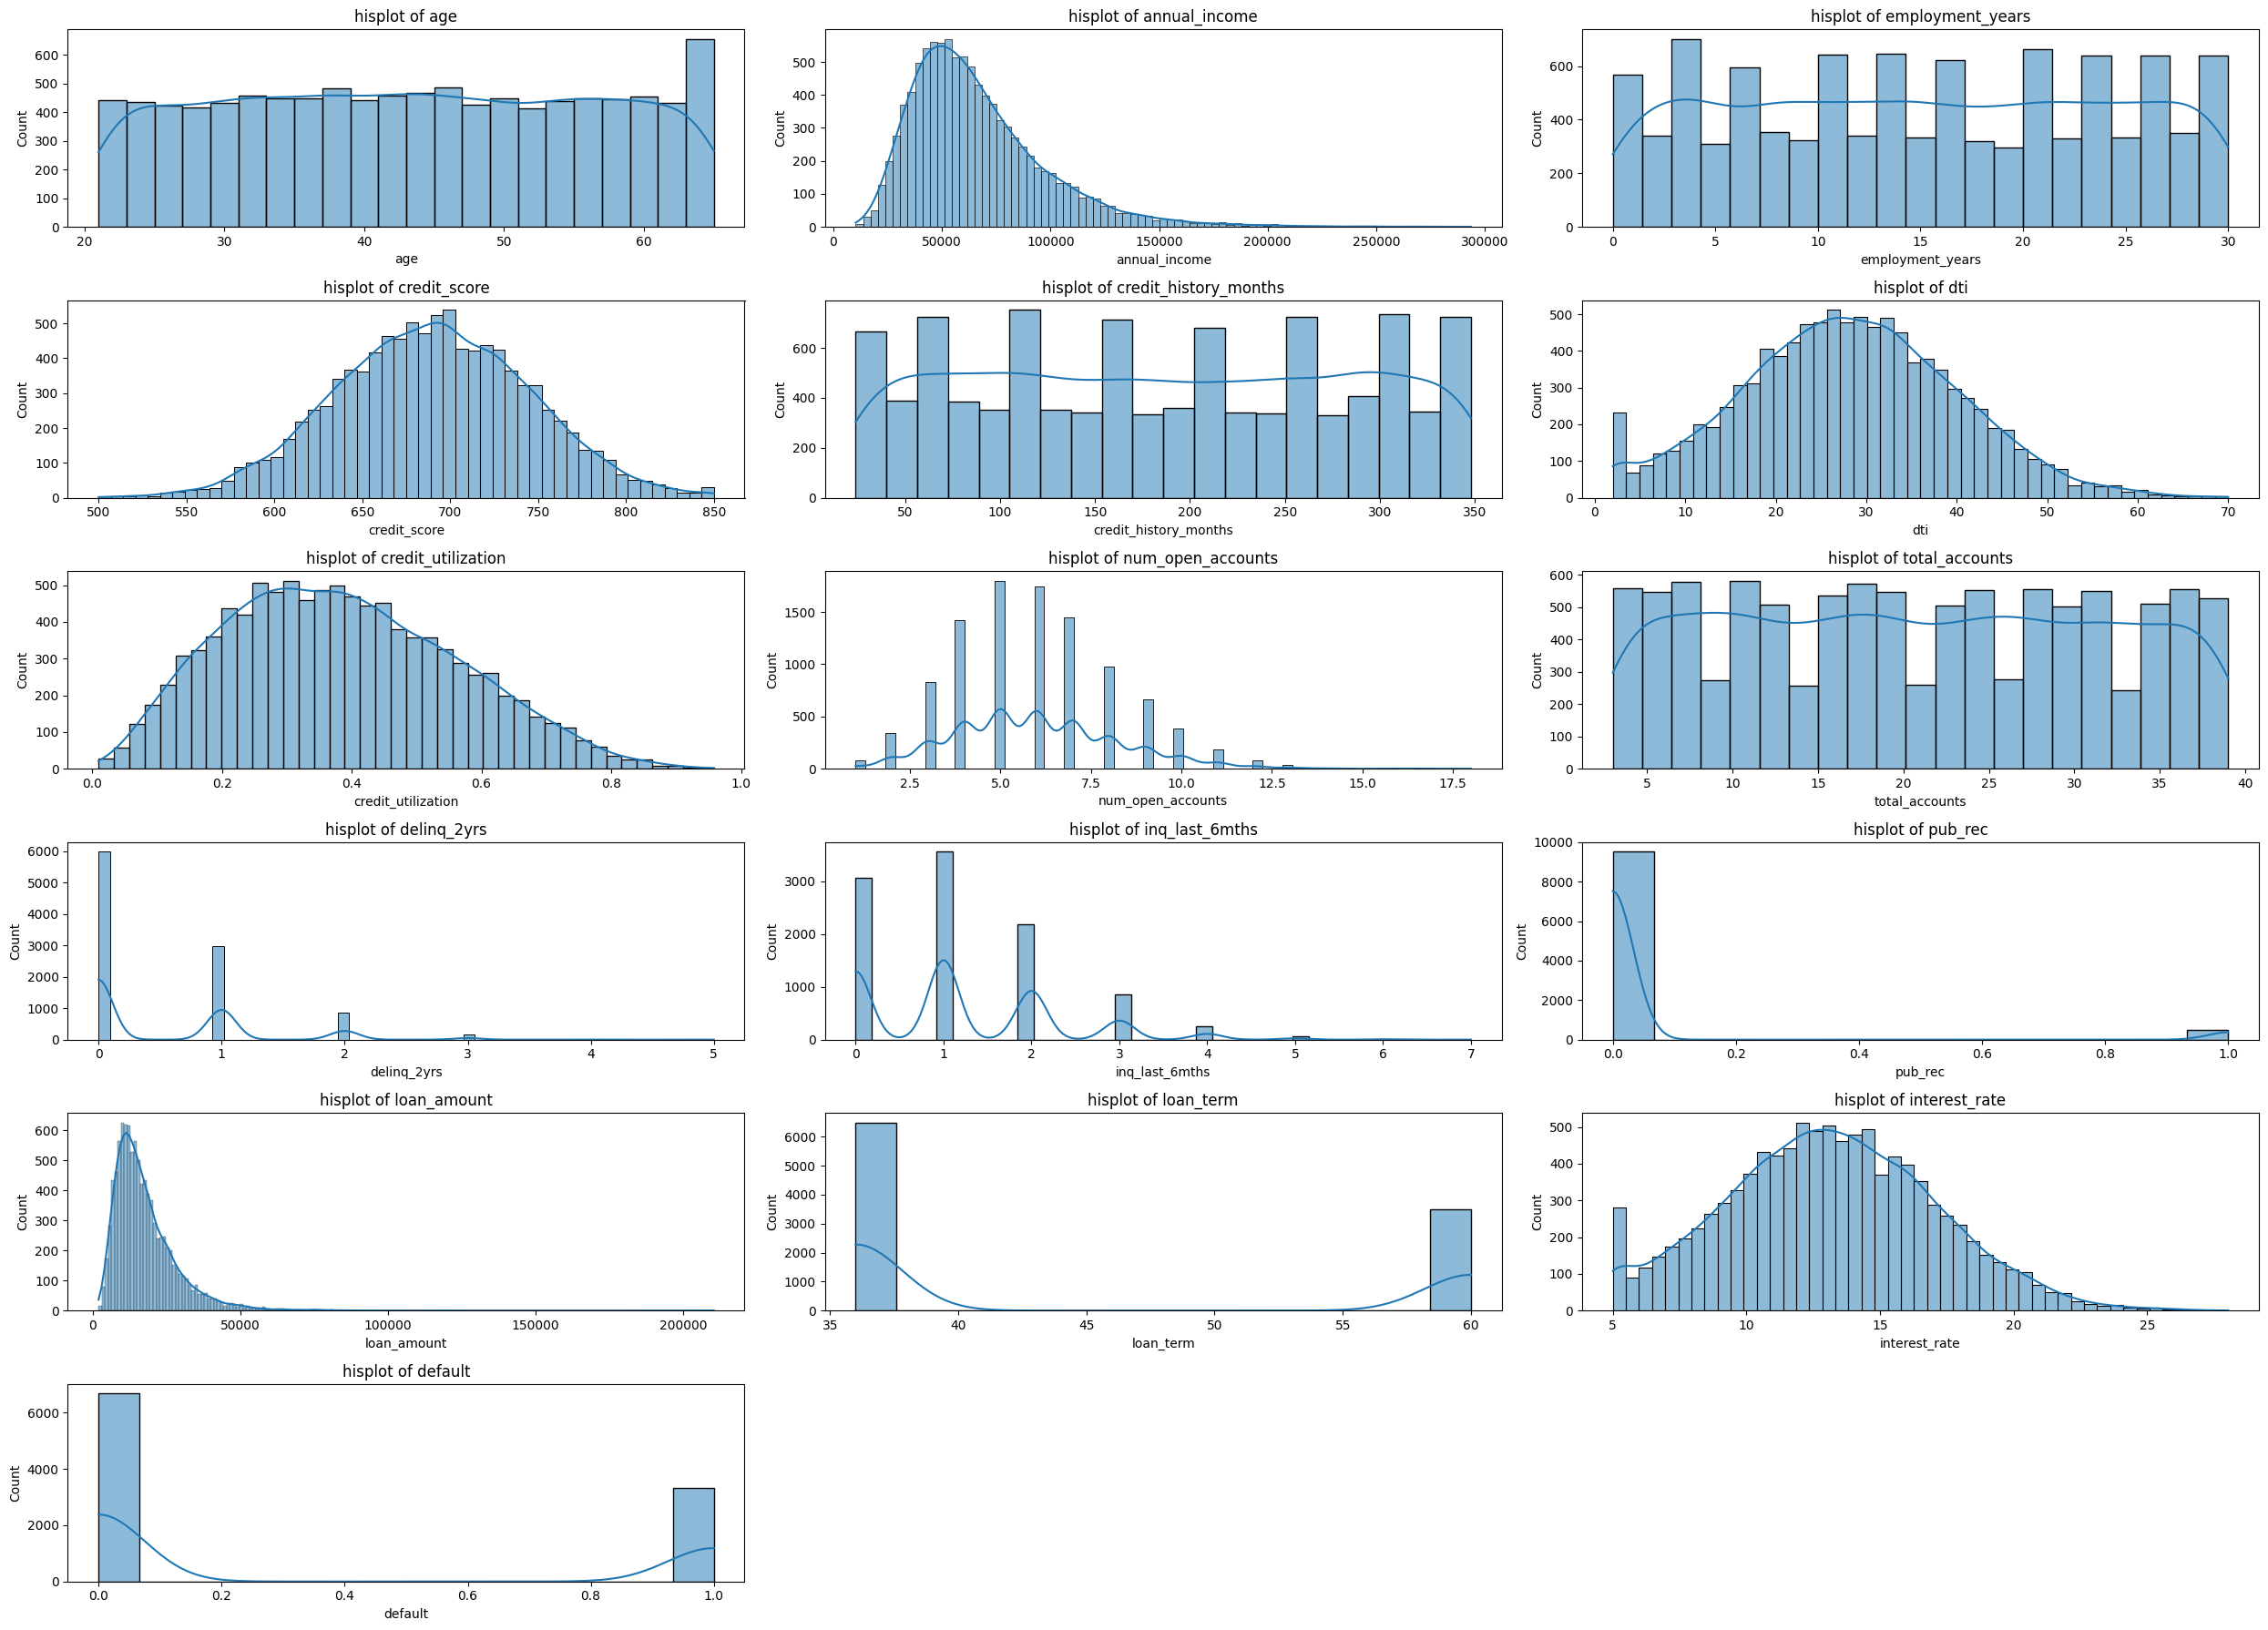

In [17]:
# let's see distribution , outliers in the num_cols

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(25,18))

for i,col in enumerate(num_cols,1):

  plt.subplot(6,3,i)
  plt.title(f'hisplot of {col}')
  sns.histplot(df_pd,x = col, kde = 10)

plt.tight_layout()
plt.show()


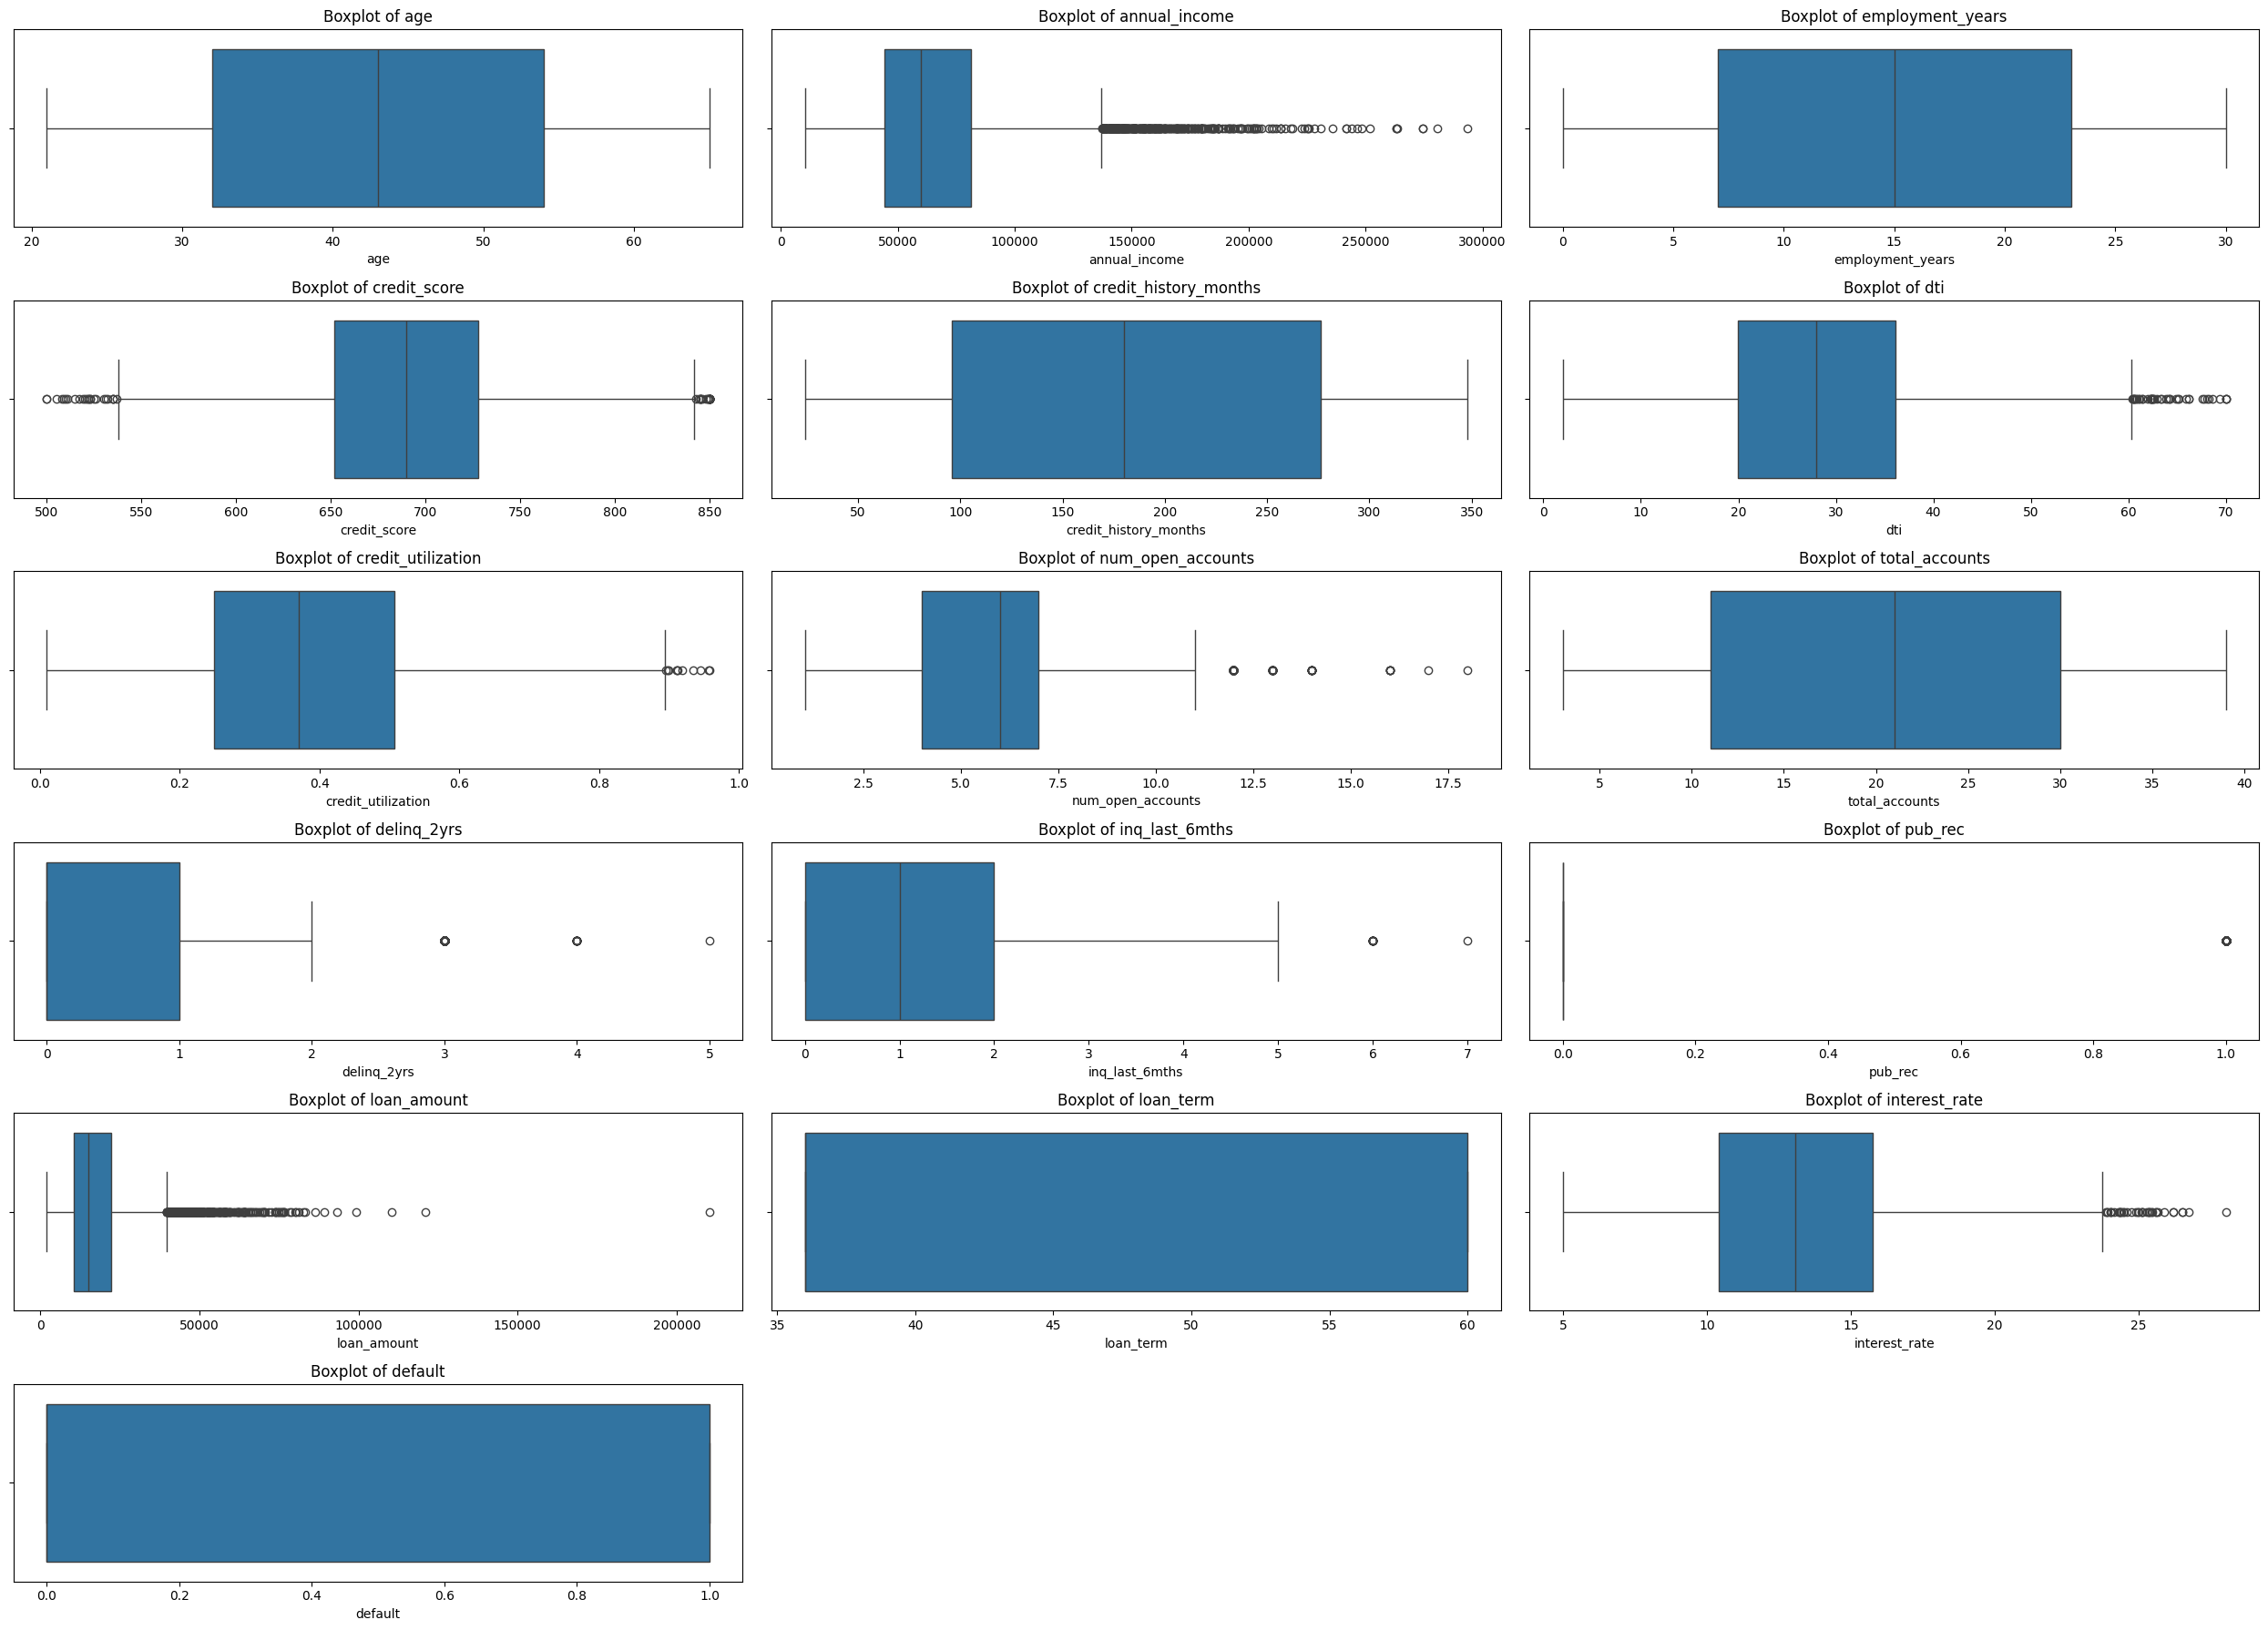

In [18]:

plt.figure(figsize=(25,18))  # we have outliers in num_cols but it can be legimate.

for i,col in enumerate(num_cols,1):

  plt.subplot(6,3,i)
  plt.title(f'Boxplot of {col}')
  sns.boxplot(df_pd[num_cols],x = col)

plt.tight_layout()
plt.show()


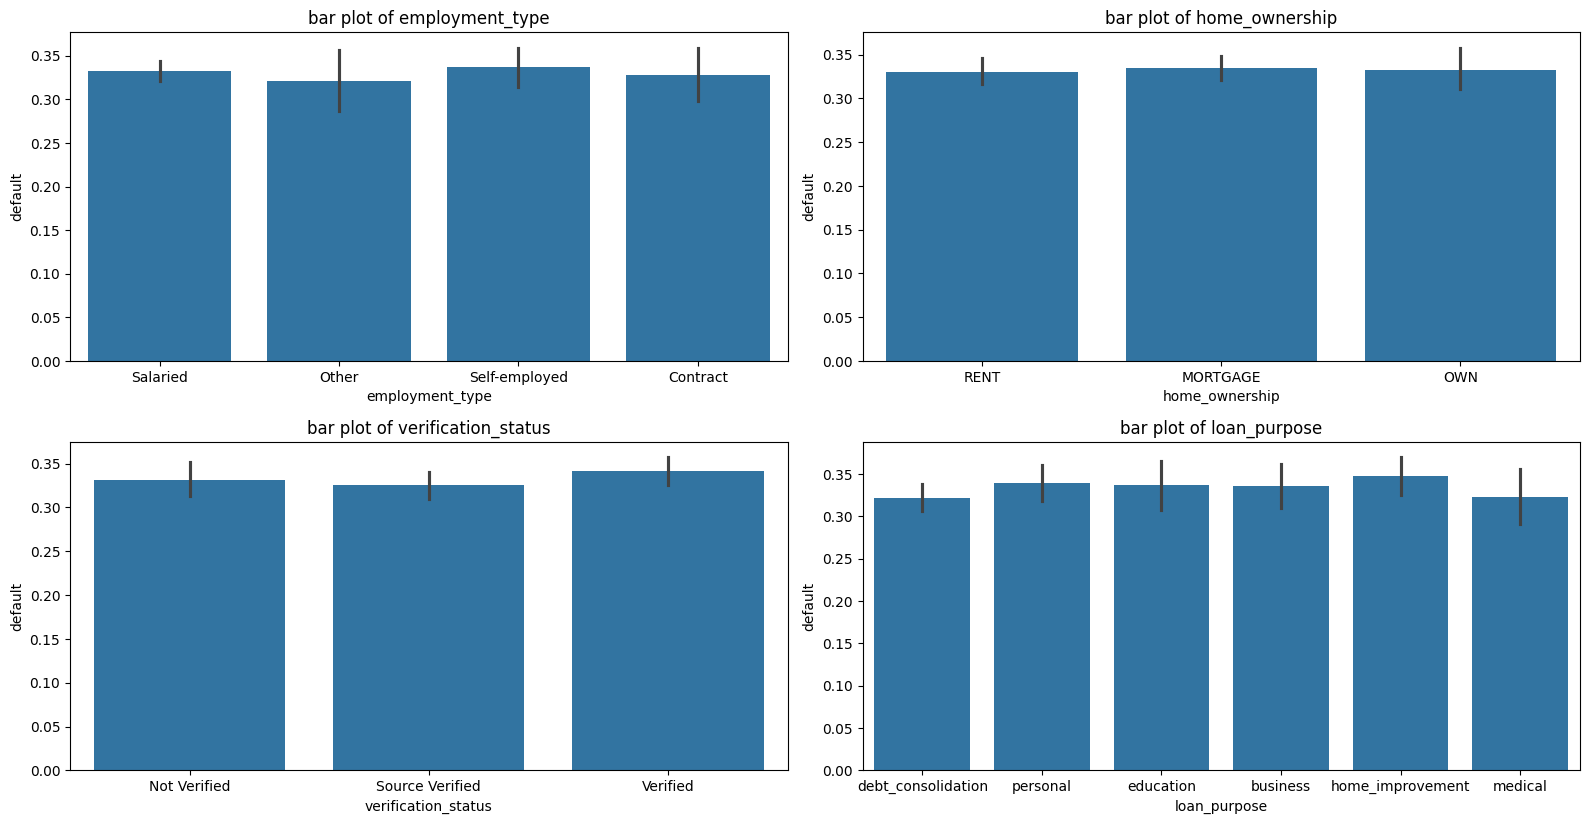

In [19]:
# create countplot/barplot of cat_cols to understand it's relation with default and to understand it's distribution

plt.figure(figsize= (16,12))

for i,col in enumerate(cat_cols,1):
  plt.subplot(3,2,i)
  plt.title(f'bar plot of {col}')
  sns.barplot(df_pd[cat_cols],x = col,y= df_pd['default'])

plt.tight_layout()
plt.show()

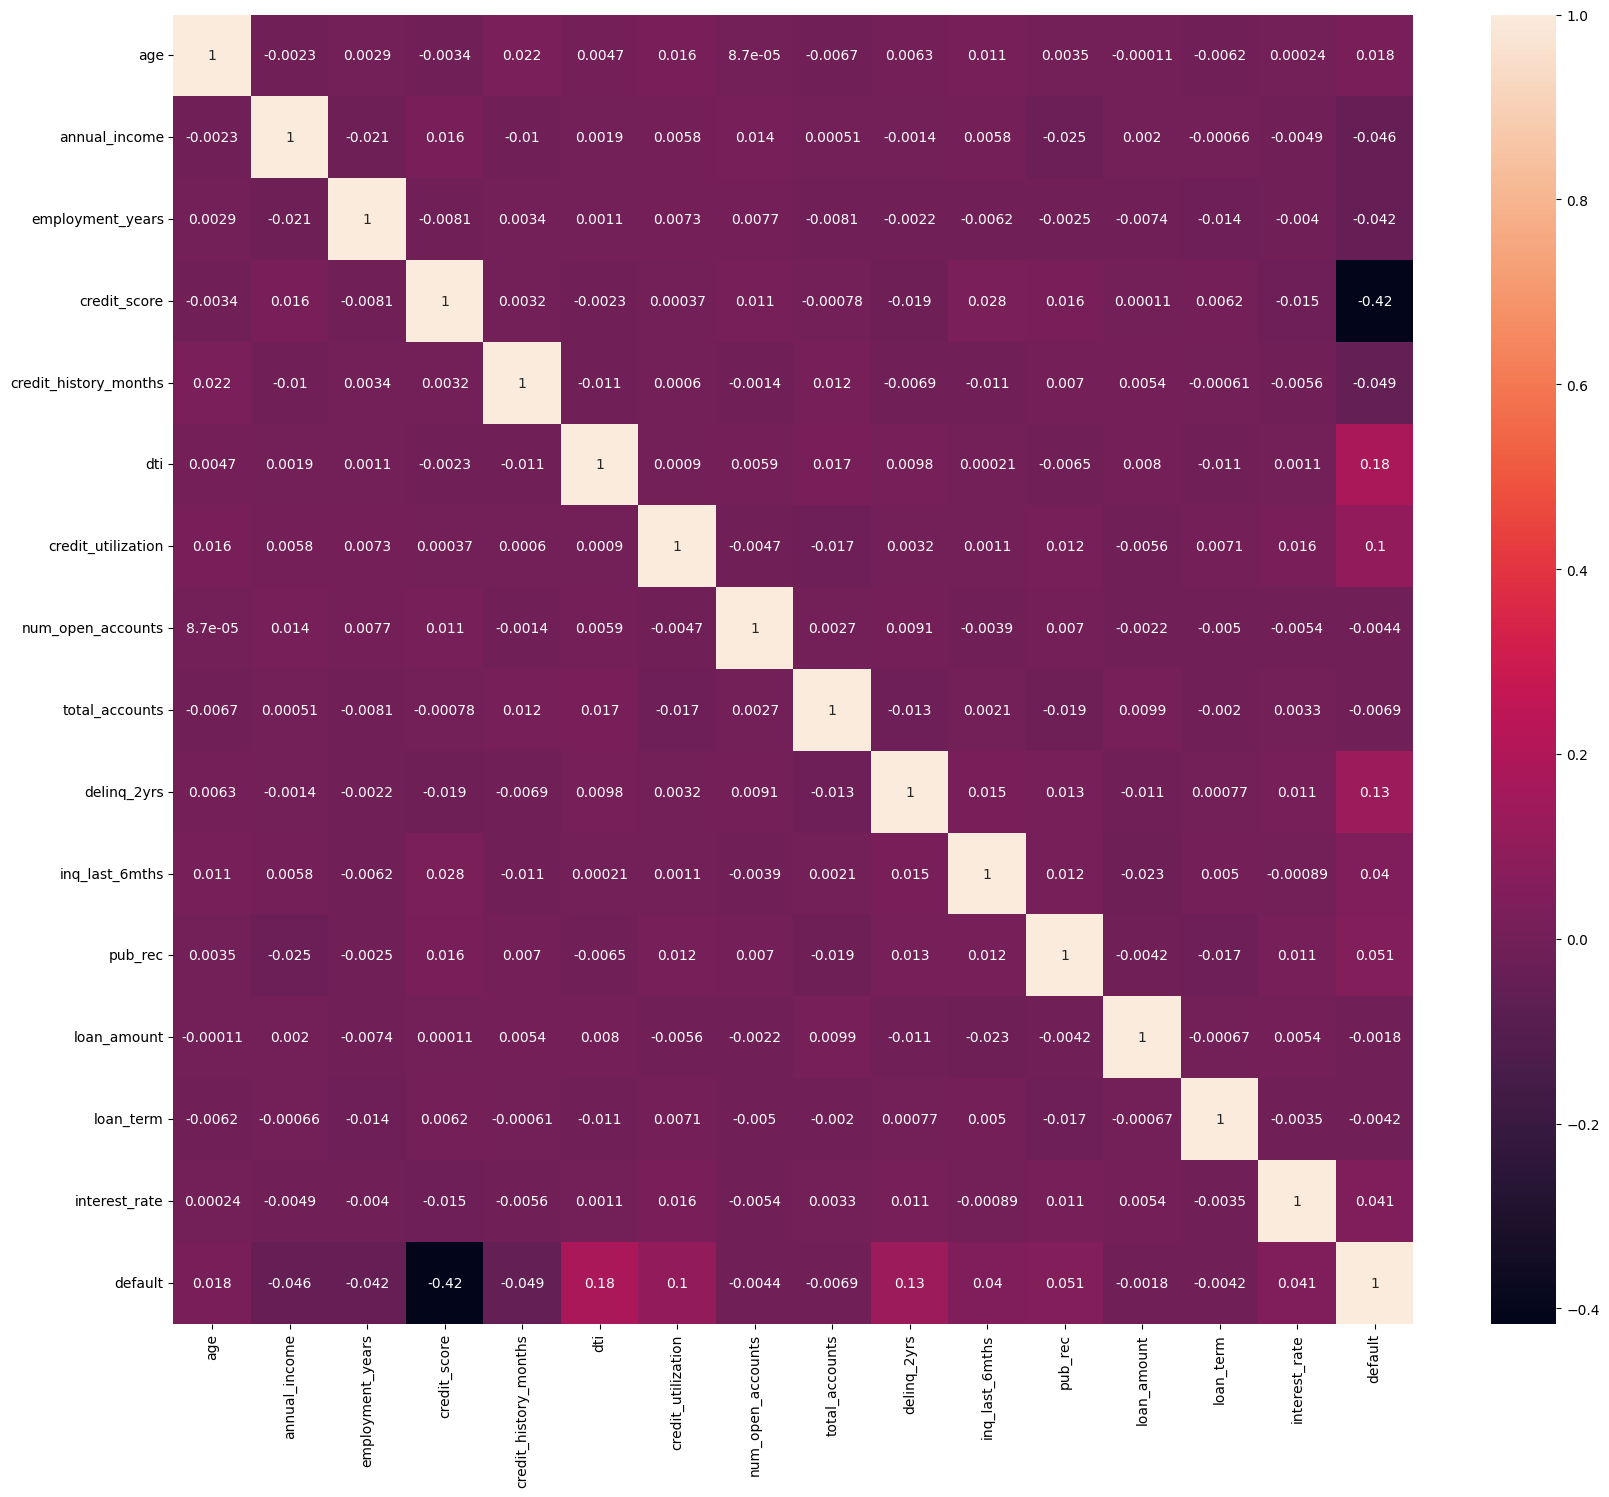

In [20]:
# understand the replationship before binning

corr_matrix = df_pd[num_cols].corr()
plt.figure(figsize=(20,17))
sns.heatmap(corr_matrix,annot =True)
plt.show()

In [21]:
# let's split into train_test in 80/20

X = df_pd.drop(columns=['default'])
y = df_pd['default']

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify = y ,random_state=42)

In [23]:
X_train.shape

(8000, 21)

In [24]:
y_train.shape

(8000,)

In [25]:
# for feature selection and to understand prediction power of predictor let's create binning

# Binning

In [26]:
num_cols  = df_pd[num_cols].drop(columns = 'default')


In [27]:
num_cols.columns

Index(['age', 'annual_income', 'employment_years', 'credit_score',
       'credit_history_months', 'dti', 'credit_utilization',
       'num_open_accounts', 'total_accounts', 'delinq_2yrs', 'inq_last_6mths',
       'pub_rec', 'loan_amount', 'loan_term', 'interest_rate'],
      dtype='object')

In [28]:
!pip install optbinning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.4/234.4 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 61.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 9.8 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0


In [29]:
from optbinning import OptimalBinning

binning_model = {}
iv_result = {}

all_cols = list(num_cols) + list(cat_cols)

for col in all_cols:

  if col in num_cols:
    optb = OptimalBinning( name = col,dtype ='numerical',monotonic_trend= 'auto')
  else:
    optb = OptimalBinning(name = col , dtype = 'categorical')

  optb.fit(X_train[col],y_train)
  binning_model[col] = optb
  table = optb.binning_table.build()
  iv_result[col] = table.loc['Totals','IV']

(CVXPY) Oct 08 04:59:20 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Oct 08 04:59:20 AM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 08 04:59:20 AM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 08 04:59:20 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


In [30]:
binning_model['credit_score'].binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 602.50)",441,0.055125,119,322,0.730159,-1.692328,0.167148,0.018710
1,"[602.50, 621.50)",403,0.050375,135,268,0.665012,-1.382612,0.104347,0.012095
2,"[621.50, 639.50)",582,0.072750,242,340,0.584192,-1.036907,0.085546,0.010239
3,"[639.50, 654.50)",616,0.077000,289,327,0.530844,-0.820433,0.056456,0.006866
4,"[654.50, 670.50)",825,0.103125,455,370,0.448485,-0.490105,0.026413,0.003269
5,"[670.50, 680.50)",536,0.067000,343,193,0.360075,-0.121859,0.001014,0.000127
6,"[680.50, 688.50)",430,0.053750,293,137,0.318605,0.063292,0.000213,0.000027
7,"[688.50, 695.50)",426,0.053250,299,127,0.298122,0.159357,0.001314,0.000164
8,"[695.50, 710.50)",824,0.103000,628,196,0.237864,0.467526,0.020533,0.002544
9,"[710.50, 725.50)",780,0.097500,606,174,0.223077,0.550925,0.026483,0.003269


In [31]:
X = X.drop(columns =['issue_d','earliest_cr_line'])

# Woe transformation

In [36]:
X_train_woe_df = pd.DataFrame(index = X_train.index)

for col in all_cols:
  X_train_woe_df[col+'_woe'] = binning_model[col].transform(X_train[col],metric = 'woe')

X_train_woe_df.head()

,age_woe,annual_income_woe,employment_years_woe,credit_score_woe,credit_history_months_woe,dti_woe,credit_utilization_woe,num_open_accounts_woe,total_accounts_woe,delinq_2yrs_woe,inq_last_6mths_woe,pub_rec_woe,loan_amount_woe,loan_term_woe,interest_rate_woe,employment_type_woe,home_ownership_woe,verification_status_woe,loan_purpose_woe
9325,-0.015678,0.102104,0.191556,2.856065,0.030112,-0.040819,-0.083326,-0.172889,-0.004555,-0.618381,0.062530,0.0,-0.043297,0.003455,-0.063198,-0.007533,0.019159,-0.028598,-0.063391
2581,-0.015678,0.102104,-0.067468,-1.692328,0.030112,-0.197003,0.153704,0.018420,-0.021365,0.214983,0.057262,0.0,-0.043297,0.003455,0.060124,-0.000296,-0.008480,-0.028598,-0.024410
7709,0.039278,0.035857,0.054125,-1.036907,0.228870,-0.360427,0.153704,0.018420,0.055740,-0.618381,0.057262,0.0,-0.043297,0.003455,-0.063198,0.108726,0.019159,-0.022073,-0.063391
4030,-0.015678,0.102104,0.072891,-1.692328,0.104105,0.468088,0.203508,0.018420,-0.021365,0.214983,-0.063485,0.0,-0.043297,0.003455,-0.063198,-0.000296,-0.017857,-0.028598,0.025684
4867,-0.015678,0.328953,-0.067468,1.646929,-0.143400,0.837448,-0.083326,0.018420,-0.021365,-0.171826,-0.201283,0.0,-0.043297,0.003455,0.060124,-0.034587,-0.017857,-0.022073,0.092026


In [37]:
X_train_woe_df.shape

(8000, 19)

In [43]:
X_train_woe_df.nunique()

,0
age_woe,6
annual_income_woe,6
employment_years_woe,6
credit_score_woe,14
credit_history_months_woe,7
dti_woe,10
credit_utilization_woe,7
num_open_accounts_woe,4
total_accounts_woe,5
delinq_2yrs_woe,3


In [45]:
X_train_woe_df = X_train_woe_df.drop(columns =['pub_rec_woe'])

In [46]:
import statsmodels.api as sm

X = sm.add_constant(X_train_woe_df)

model = sm.Logit(y_train,X).fit()

print(model.summary())




Optimization terminated successfully.
         Current function value: 0.483055
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                 8000
Model:                          Logit   Df Residuals:                     7981
Method:                           MLE   Df Model:                           18
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.2404
Time:                        05:34:35   Log-Likelihood:                -3864.4
converged:                       True   LL-Null:                       -5087.5
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                        -0.7065      0.029    -24.704      0.000      -0.

In [75]:
feature_df = pd.DataFrame({
  'varaible': X_train_woe_df.columns,
  'IV' : [iv_result.get(col.replace('_woe',''),np.nan) for col in X_train_woe_df.columns],
  'coefficient' : model.params.drop('const').reindex(X_train_woe_df.columns).values,
  'p_value': model.pvalues.drop('const').reindex(X_train_woe_df.columns).values
})

feature_df.sort_values('IV', ascending = False)

,varaible,IV,coefficient,p_value
3,credit_score_woe,1.013367,-1.113685,2.051489e-262
5,dti_woe,0.182776,-1.279016,3.061184e-79
9,delinq_2yrs_woe,0.078851,-1.257525,1.867943e-36
6,credit_utilization_woe,0.061330,-1.274753,4.807240e-28
1,annual_income_woe,0.020385,-1.229885,4.675351e-10
4,credit_history_months_woe,0.016573,-1.211594,2.621641e-08
13,interest_rate_woe,0.013846,-1.054206,9.953713e-06
2,employment_years_woe,0.013097,-1.427830,5.267481e-09
10,inq_last_6mths_woe,0.008337,-1.659771,4.974231e-08
11,loan_amount_woe,0.005976,-1.387220,1.623733e-04


In [76]:
Feature_selection = ['credit_score_woe','dti_woe','delinq_2yrs_woe','credit_utilization_woe','annual_income_woe','credit_history_months_woe','interest_rate_woe','employment_years_woe','inq_last_6mths_woe','loan_amount_woe','num_open_accounts_woe','age_woe']

In [78]:
Feature_selection

['credit_score_woe',
 'dti_woe',
 'delinq_2yrs_woe',
 'credit_utilization_woe',
 'annual_income_woe',
 'credit_history_months_woe',
 'interest_rate_woe',
 'employment_years_woe',
 'inq_last_6mths_woe',
 'loan_amount_woe',
 'num_open_accounts_woe',
 'age_woe']

In [80]:
X_train_final = X_train_woe_df[Feature_selection]

X_train_final = sm.add_constant(X_train_final)

final_model = sm.Logit(y_train,X_train_final).fit()

print(final_model.summary())

Optimization terminated successfully.
         Current function value: 0.483783
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                 8000
Model:                          Logit   Df Residuals:                     7987
Method:                           MLE   Df Model:                           12
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                  0.2393
Time:                        06:47:50   Log-Likelihood:                -3870.3
converged:                       True   LL-Null:                       -5087.5
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                        -0.7066      0.029    -24.730      0.000      -0.

In [81]:
train_pd = final_model.predict(X_train_final)


In [82]:
X_test_woe_df = pd.DataFrame(index=X_test.index)

for col in Feature_selection:
    original_col = col.replace('_woe', '')

    X_test_woe_df[col] = binning_model[original_col].transform(
        X_test[original_col],
        metric='woe'
    )

In [83]:
X_test_final = X_test_woe_df[Feature_selection]

X_test_final = sm.add_constant(X_test_final)

In [84]:
test_pd = final_model.predict(X_test_final)

In [87]:
from sklearn.metrics import roc_auc_score

train_auc = roc_auc_score(y_train, train_pd)
test_auc = roc_auc_score(y_test, test_pd)

print("Train AUC:", train_auc)
print("Test AUC:", test_auc)

Train AUC: 0.8212019515079835
Test AUC: 0.7958018642110896


In [88]:
from scipy.stats import ks_2samp

train_ks = ks_2samp(
    train_pd[y_train == 1],
    train_pd[y_train == 0]
).statistic

test_ks = ks_2samp(
    test_pd[y_test == 1],
    test_pd[y_test == 0]
).statistic

print("Train KS:", train_ks)
print("Test KS:", test_ks)

Train KS: 0.5015699360761454
Test KS: 0.46144011714679956


In [89]:
train_gini = 2 * train_auc - 1
test_gini = 2 * test_auc - 1

print("Train Gini:", train_gini)
print("Test Gini:", test_gini)

Train Gini: 0.642403903015967
Test Gini: 0.5916037284221791


In [90]:
print(train_pd.describe())
print(test_pd.describe())

count    8000.000000
mean        0.332500
std         0.248892
min         0.002152
25%         0.117507
50%         0.278941
75%         0.517692
max         0.975866
dtype: float64
count    2000.000000
mean        0.345859
std         0.247707
min         0.002274
25%         0.126856
50%         0.299895
75%         0.540313
max         0.951382
dtype: float64


In [91]:
print("Train PD range:", train_pd.min(), train_pd.max())
print("Test PD range:", test_pd.min(), test_pd.max())

Train PD range: 0.002151562584574737 0.975865789743238
Test PD range: 0.00227415248087534 0.9513822130566638


In [92]:
calib_df = pd.DataFrame({
    'actual': y_test.values,
    'predicted_pd': test_pd.values
})

calib_df['decile'] = pd.qcut(
    calib_df['predicted_pd'],
    q=10,
    duplicates='drop'
)

calibration = calib_df.groupby('decile', observed=True).agg(
    customers=('actual', 'count'),
    actual_defaults=('actual', 'sum'),
    actual_default_rate=('actual', 'mean'),
    avg_predicted_pd=('predicted_pd', 'mean')
).reset_index()

calibration

,decile,customers,actual_defaults,actual_default_rate,avg_predicted_pd
0,"(0.0012699999999999999, 0.0483]",200,3,0.015,0.024312
1,"(0.0483, 0.0994]",200,21,0.105,0.075071
2,"(0.0994, 0.158]",200,26,0.130,0.128002
3,"(0.158, 0.227]",200,33,0.165,0.193219
4,"(0.227, 0.3]",200,47,0.235,0.263493
5,"(0.3, 0.382]",200,73,0.365,0.341933
6,"(0.382, 0.488]",200,81,0.405,0.436736
7,"(0.488, 0.588]",200,108,0.540,0.538422
8,"(0.588, 0.72]",200,125,0.625,0.651348
9,"(0.72, 0.951]",200,148,0.740,0.806048


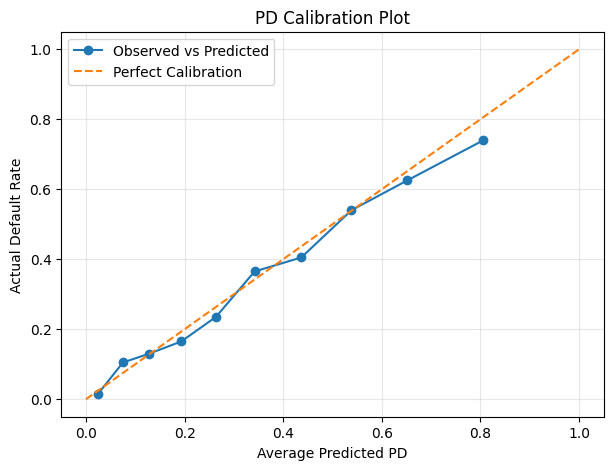

In [93]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    calibration['avg_predicted_pd'],
    calibration['actual_default_rate'],
    marker='o',
    label='Observed vs Predicted'
)

# Perfect calibration line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Perfect Calibration'
)

plt.xlabel('Average Predicted PD')
plt.ylabel('Actual Default Rate')
plt.title('PD Calibration Plot')
plt.legend()
plt.grid(alpha=0.3)

plt.show()